### Optimization parameter tuning

In [12]:
# Allows Python to find mosh_src if this notebook is moved
import sys
sys.path.insert(0, "/Users/seanmullane/Desktop/Research_2025/modulated_shielding")

# Add functionality to parse folders
import os

# Import matplotlib and numpy - helpful Python libraries for scientific computing
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.colors as colors
import matplotlib.patches as patches
from matplotlib import ticker
from math import pi
from decimal import Decimal

# Import all MOSH plotting functions
from mosh_src.plotting_functions import *

In [13]:
## Define basic optimization parameters ##
D_min = 2 # Gy
D_max = 15 # Gy

# 100 cost/cGy = 100 cost/(Gy * 1e-2) = 1e4 cost/Gy
M_l = 1e4 # cost/Gy
M_u = 1e4 # cost/Gy

num_dose_points = 8

In [5]:
### Generate and save randomly distributed dose points ###
num_points = 1000
origin = (2, 0, 1)
__ = generate_points_uniform_sphere(num_points, origin, save=True, save_name="dose_point_file_12-20-2025.npy")

In [14]:
num_dwell_pos_1 = 51

# Unpack the dose rate matrix from the locally stored file
D_1 = np.load("D_1mmSpace_1e6_1e3dosePoints.npy")
#D_1 = np.load("D_1mmSpace_1e6.npy")

func_1, x_1, __ = linear_penalty(D_min, D_max, M_l, M_u, num_dose_points, num_dwell_pos_1, D_1)

# Plot dwell time vs dwell position index
dwell_pos_cm = np.array([x for x in np.arange(-25, 26)])

fig5, ax5 = plt.subplots()
ax5.bar(dwell_pos_cm, x_1)
ax5.set_xlabel('dwell position pos (cm)')
ax5.set_ylabel('dwell position time (sec)')
plt.show()

FileNotFoundError: [Errno 2] No such file or directory: 'D_1mmSpace_1e6_1e3dosePoints.npy'

#### Generating more dose points

In [40]:
# I think one reason my dwell time graphs are "sparse" is because I'm only working with 8 dosing points
# Will use this section to set up a new model: pick 500 - 1e3 points randomly distributed on surface of a 
# sphere, and use these as dosing points --> see https://mathworld.wolfram.com/SpherePointPicking.html
num_dose_points = 1000
mu, sigma = 0, 1
dose_points = []
origin = (2, 0, 1) # cm
for i in range(num_dose_points):
    X = np.random.normal(mu, sigma)
    Y = np.random.normal(mu, sigma)
    Z = np.random.normal(mu, sigma)

    norm = np.sqrt([(X)**2 + (Y)**2 + (Z)**2])
    p = ((X/norm) + origin[0], (Y/norm) + origin[1], (Z/norm) + origin[2])
    dose_points.append(p)

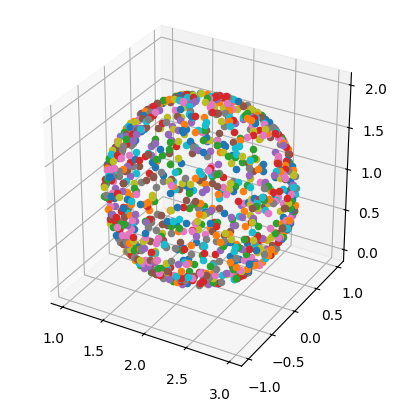

In [41]:
# Plotting to check uniform distribution over sphere surface
fig = plt.figure()
ax = fig.add_subplot(projection='3d')
ax.set_aspect('equal')
for p in dose_points:
    ax.scatter(p[0], p[1], p[2])
plt.show()

# Looks good!

In [2]:
test = "test_string_-1.csv.npy"
s = os.path.splitext(test)[0]
s2 = os.path.splitext(s)[0]
print(s, s2)

test_string_-1.csv test_string_-1


In [11]:
for i in range(-25, 26, 1):
    x = i**2 + i
    print(x)

# (i_1)^2 + i_1 = (i_1 + n)^2 + (i_1 + n)
# ---> (i_1)^2 + i_1 = (i_1)^2 + 2*i_1*n + n^2 + i_1 + n
# ---> (i_1)^2 = (i_1)^2 + 2*i_1*n + n^2 + n
# ---> 0 = 2*i_1*n + n^2 + n
# ---> 0 = n*(2*i + n + 1)
# ---> n = 0, or 
# ---> 2*i + n + 1 = 0 ---> 2*i + n = -1
# ---> n = -(1 + 2*i)
# i = 10 ---> n = -(1 + 20) = -21

600
552
506
462
420
380
342
306
272
240
210
182
156
132
110
90
72
56
42
30
20
12
6
2
0
0
2
6
12
20
30
42
56
72
90
110
132
156
182
210
240
272
306
342
380
420
462
506
552
600
650
